# STAGE 2 — TASK 1: HỌC KHÔNG GIÁM SÁT & GIẢM CHIỀU DỮ LIỆU (PCA)

**Dự án:** CGV Movie Analytics  
**Dataset đầu vào:** `cgv_eda_cleaned.csv`

## Mục tiêu
1. Chuẩn hóa đặc trưng bằng `StandardScaler`.
2. Tính `Explained Variance Ratio` và `Cumulative Explained Variance Ratio`.
3. Chọn số thành phần chính tối thiểu để đạt ít nhất 85% phương sai; đồng thời kiểm tra kết quả với ngưỡng 95%.
4. Vẽ biểu đồ phương sai tích lũy và biểu đồ phân tán PC1–PC2.
5. Lưu dữ liệu sau giảm chiều và các thành phần cần thiết để dùng tiếp cho Task 2.

**Lưu ý về dữ liệu:** dataset CGV hiện không có dữ liệu hành vi hoặc mã khách hàng, nên PCA ở đây giảm chiều các đặc trưng của **suất chiếu/phim**, không phải đặc trưng khách hàng. PCA là bước giảm chiều, không phải mô hình dự đoán nhãn.


## 1. Import thư viện




In [13]:
# 2. Import thư viện

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42


## 3. Đọc dataset

Đặt file CSV cùng thư mục với Notebook. Nếu tên file khác, sửa biến `FILE_PATH` bên dưới.


In [14]:
FILE_PATH = "cgv_eda_cleaned.csv"

if not os.path.exists(FILE_PATH):
    # Thử tên file thường dùng nếu file chính không nằm cùng thư mục
    alternatives = [
        "cgv_eda_cleaned.csv",
        "/mnt/data/cgv_eda_cleaned.csv"
    ]
    for path in alternatives:
        if os.path.exists(path):
            FILE_PATH = path
            break

df = pd.read_csv(FILE_PATH)

print("Đường dẫn file:", FILE_PATH)
print("Kích thước dataset:", df.shape)
print("\nDanh sách cột:")
print(df.columns.tolist())

display(df.head())


Đường dẫn file: cgv_eda_cleaned.csv
Kích thước dataset: (1172, 15)

Danh sách cột:
['MovieName', 'Cinema', 'ShowDate', 'Format', 'ShowTime', 'GeneratedText', 'MovieURL', 'Rating', 'Director', 'Actors', 'Genre', 'ReleaseDate', 'Duration', 'Language', 'DurationMinutes']


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,2D Lồng Tiếng Việt,12:50,"Hôm nay, tôi đã có cơ hội xem suất chiếu LAPUT...",https://www.cgv.vn/default/laputa.html,K,Hayao Miyazaki,"Mayumi Tanaka, Keiko Yokozawa, Kotoe Hatsui, M...",Hoạt Hình,2026-09-25,129 phút,Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,129.0
2,MARNIE YÊU DẤU,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt,16:50,"Hôm nay, tôi đã có cơ hội xem suất chiếu ""MARN...",https://www.cgv.vn/default/marnie-yeu-dau.html,K,Hiromasa Yonebayashi,"Sara Takatsuki, Kasumi Arimura, Hana Sugisaki,...",Hoạt Hình,2026-09-18,103 phút,Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,103.0
3,TRẠI BUÔN NGƯỜI,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh,12:00,"Tôi vừa có dịp xem suất chiếu ""TRẠI BUÔN NGƯỜI...",https://www.cgv.vn/default/trai-buon-nguoi.html,T18,Toni Dương Bảo Anh,"Steven Nguyễn, Quách Ngọc Ngoan, Tùng Mint, Hu...","Hành Động, Hồi hộp",2026-09-25,135 phút,Tiếng Việt,135.0
4,TRẠI BUÔN NGƯỜI,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh,15:10,Trải nghiệm xem suất chiếu TRẠI BUÔN NGƯỜI tại...,https://www.cgv.vn/default/trai-buon-nguoi.html,T18,Toni Dương Bảo Anh,"Steven Nguyễn, Quách Ngọc Ngoan, Tùng Mint, Hu...","Hành Động, Hồi hộp",2026-09-25,135 phút,Tiếng Việt,135.0


## 4. Kiểm tra dữ liệu và chọn đặc trưng

PCA chỉ xử lý dữ liệu số. Với dataset CGV này, Notebook sẽ tạo một số đặc trưng có ý nghĩa:
- `DurationMinutes`: thời lượng phim tính bằng phút.
- `ShowMonth`, `ShowDayOfWeek`: tháng và thứ trong tuần của suất chiếu.
- `ShowHour`, `ShowMinute`: giờ và phút chiếu.
- `ReleaseMonth`, `DaysFromReleaseToShow`: tháng phát hành và số ngày từ phát hành đến ngày chiếu.
- Các cột `Format`, `Rating`, `Genre`, `Language`, `Cinema`: mã hóa bằng one-hot encoding.

Không đưa `MovieName`, `Actors`, `Director`, `GeneratedText` và `MovieURL` trực tiếp vào PCA vì đây là văn bản định danh/dài, cần một phương pháp biểu diễn văn bản riêng nếu muốn khai thác.


In [15]:
print("Kiểu dữ liệu:")
display(df.dtypes.astype(str).to_frame("Data type"))

print("Số giá trị thiếu ban đầu:")
display(df.isna().sum().to_frame("Missing values"))


Kiểu dữ liệu:


,Data type
MovieName,object
Cinema,object
ShowDate,object
Format,object
ShowTime,object
GeneratedText,object
MovieURL,object
Rating,object
Director,object
Actors,object


Số giá trị thiếu ban đầu:


,Missing values
MovieName,0
Cinema,0
ShowDate,0
Format,0
ShowTime,0
GeneratedText,0
MovieURL,0
Rating,0
Director,0
Actors,0


In [16]:
# Tạo bản sao để không làm thay đổi dataset gốc
df_work = df.copy()

# Chuẩn hóa các cột ngày giờ nếu có
if "ShowDate" in df_work.columns:
    df_work["ShowDate"] = pd.to_datetime(df_work["ShowDate"], errors="coerce")

if "ReleaseDate" in df_work.columns:
    df_work["ReleaseDate"] = pd.to_datetime(df_work["ReleaseDate"], errors="coerce")

# Tạo đặc trưng thời gian từ ShowDate
if "ShowDate" in df_work.columns:
    df_work["ShowMonth"] = df_work["ShowDate"].dt.month
    df_work["ShowDayOfWeek"] = df_work["ShowDate"].dt.dayofweek

# Tạo đặc trưng thời gian từ ShowTime
if "ShowTime" in df_work.columns:
    time_text = df_work["ShowTime"].astype("string").str.strip()
    parsed_time = pd.to_datetime(time_text, format="%H:%M", errors="coerce")
    # Nếu dữ liệu có định dạng khác HH:MM, thử để pandas tự nhận diện
    mask = parsed_time.isna() & time_text.notna()
    if mask.any():
        parsed_time.loc[mask] = pd.to_datetime(time_text.loc[mask], errors="coerce")
    df_work["ShowHour"] = parsed_time.dt.hour
    df_work["ShowMinute"] = parsed_time.dt.minute

# Tạo đặc trưng từ ngày phát hành
if "ReleaseDate" in df_work.columns:
    df_work["ReleaseMonth"] = df_work["ReleaseDate"].dt.month

if "ShowDate" in df_work.columns and "ReleaseDate" in df_work.columns:
    df_work["DaysFromReleaseToShow"] = (
        df_work["ShowDate"] - df_work["ReleaseDate"]
    ).dt.days

# Chuyển Duration sang số phút nếu DurationMinutes chưa có hoặc có giá trị thiếu
if "DurationMinutes" not in df_work.columns:
    if "Duration" in df_work.columns:
        df_work["DurationMinutes"] = pd.to_numeric(
            df_work["Duration"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
            errors="coerce"
        )
elif "Duration" in df_work.columns:
    duration_parsed = pd.to_numeric(
        df_work["Duration"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
        errors="coerce"
    )
    df_work["DurationMinutes"] = pd.to_numeric(
        df_work["DurationMinutes"], errors="coerce"
    ).fillna(duration_parsed)

# Chuyển Rating nếu dữ liệu là số; nếu Rating là phân loại như K, T13, T16 thì giữ dạng category
if "Rating" in df_work.columns:
    rating_numeric = pd.to_numeric(df_work["Rating"], errors="coerce")
    if rating_numeric.notna().sum() > 0 and rating_numeric.notna().mean() >= 0.8:
        df_work["RatingNumeric"] = rating_numeric

numeric_candidates = [
    "DurationMinutes", "ShowMonth", "ShowDayOfWeek",
    "ShowHour", "ShowMinute", "ReleaseMonth", "DaysFromReleaseToShow",
    "RatingNumeric"
]
categorical_candidates = ["Cinema", "Format", "Rating", "Genre", "Language"]

numeric_cols = [
    col for col in numeric_candidates
    if col in df_work.columns and pd.to_numeric(df_work[col], errors="coerce").notna().any()
]
categorical_cols = [
    col for col in categorical_candidates
    if col in df_work.columns
]

print("Đặc trưng số được chọn:", numeric_cols)
print("Đặc trưng phân loại được chọn:", categorical_cols)

if len(numeric_cols) + len(categorical_cols) == 0:
    raise ValueError("Không tìm thấy đặc trưng phù hợp. Hãy kiểm tra lại tên cột trong dataset.")


Đặc trưng số được chọn: ['DurationMinutes', 'ShowMonth', 'ShowDayOfWeek', 'ShowHour', 'ShowMinute', 'ReleaseMonth', 'DaysFromReleaseToShow']
Đặc trưng phân loại được chọn: ['Cinema', 'Format', 'Rating', 'Genre', 'Language']


## 5. Xử lý giá trị thiếu và mã hóa dữ liệu

- Đặc trưng số: điền bằng median của cột để hạn chế ảnh hưởng của giá trị cực đoan.
- Đặc trưng phân loại: điền `"Unknown"` rồi dùng `get_dummies()` để chuyển thành số.
- Loại bỏ cột chỉ có một giá trị duy nhất vì cột đó không cung cấp thông tin phân biệt cho PCA.

Đây là bước chuẩn bị đầu vào cho PCA, không phải thay thế toàn bộ quy trình làm sạch dữ liệu của Stage 1.


In [17]:
X = df_work[numeric_cols + categorical_cols].copy()

# Chuyển các cột số về numeric và điền median
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    median_value = X[col].median()
    if pd.isna(median_value):
        # Nếu cột hoàn toàn thiếu thì không thể dùng làm đặc trưng
        X = X.drop(columns=[col])
    else:
        X[col] = X[col].fillna(median_value)

# Điền thiếu cho cột phân loại
for col in categorical_cols:
    X[col] = X[col].fillna("Unknown").astype(str)

# One-hot encoding cho các cột phân loại
X = pd.get_dummies(X, columns=[c for c in categorical_cols if c in X.columns], dtype=int)

# Bảo đảm toàn bộ dữ liệu là số
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Xử lý các giá trị thiếu phát sinh (nếu có)
for col in X.columns:
    if X[col].isna().any():
        median_value = X[col].median()
        X[col] = X[col].fillna(0 if pd.isna(median_value) else median_value)

# Bỏ các cột hằng số
constant_cols = [col for col in X.columns if X[col].nunique(dropna=False) <= 1]
if constant_cols:
    X = X.drop(columns=constant_cols)

if X.shape[1] < 2:
    raise ValueError("Cần ít nhất 2 đặc trưng biến thiên để vẽ PCA 2D. Hãy kiểm tra dữ liệu đầu vào.")

print("Kích thước ma trận đặc trưng sau mã hóa:", X.shape)
print("Còn giá trị thiếu không?", X.isna().any().any())
print("Một số tên đặc trưng:")
print(X.columns.tolist()[:30])

display(X.head())


Kích thước ma trận đặc trưng sau mã hóa: (1172, 57)
Còn giá trị thiếu không? False
Một số tên đặc trưng:
['DurationMinutes', 'ShowMonth', 'ShowDayOfWeek', 'ShowHour', 'ShowMinute', 'ReleaseMonth', 'DaysFromReleaseToShow', 'Cinema_CGV Crescent Mall', 'Cinema_CGV Hùng Vương Plaza', 'Cinema_CGV Thảo Điền Pearl', 'Cinema_CGV Vincom Thủ Đức', 'Cinema_CGV Vivo City', 'Format_2D Lồng Tiếng Việt', 'Format_2D Phụ Đề Anh', 'Format_2D Phụ Đề Anh & Việt', 'Format_2D Phụ Đề Anh | Rạp Cine & Living Room', 'Format_2D Phụ Đề Anh | Rạp GOLD CLASS', 'Format_2D Phụ Đề Anh | Rạp Lamour', 'Format_2D Phụ Đề Anh | Rạp STARIUM', 'Format_2D Phụ Đề Việt', 'Format_2D Phụ Đề Việt\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t | Rạp Infinity Vision', 'Format_2D Phụ Đề Việt | Rạp Cine & Living Room', 'Format_2D Phụ Đề Việt | Rạp Lamour', 'Format_2D Phụ Đề Việt | Rạp STARIUM', 'Format_2D Phụ Đề Việt | Rạp STARIUM\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision', 'Format_4DX2D Lồng Tiếng Việt | Rạp 4DX', 'Format_4DX2D Phụ Đề Anh 

,DurationMinutes,ShowMonth,ShowDayOfWeek,ShowHour,ShowMinute,ReleaseMonth,DaysFromReleaseToShow,Cinema_CGV Crescent Mall,Cinema_CGV Hùng Vương Plaza,Cinema_CGV Thảo Điền Pearl,Cinema_CGV Vincom Thủ Đức,Cinema_CGV Vivo City,Format_2D Lồng Tiếng Việt,Format_2D Phụ Đề Anh,Format_2D Phụ Đề Anh & Việt,Format_2D Phụ Đề Anh | Rạp Cine & Living Room,Format_2D Phụ Đề Anh | Rạp GOLD CLASS,Format_2D Phụ Đề Anh | Rạp Lamour,Format_2D Phụ Đề Anh | Rạp STARIUM,Format_2D Phụ Đề Việt,Format_2D Phụ Đề Việt\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t | Rạp Infinity Vision,Format_2D Phụ Đề Việt | Rạp Cine & Living Room,Format_2D Phụ Đề Việt | Rạp Lamour,Format_2D Phụ Đề Việt | Rạp STARIUM,Format_2D Phụ Đề Việt | Rạp STARIUM\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision,Format_4DX2D Lồng Tiếng Việt | Rạp 4DX,Format_4DX2D Phụ Đề Anh | Rạp 4DX,Format_4DX2D Phụ Đề Việt | Rạp 4DX,Format_4DX2D Phụ Đề Việt | Rạp 4DX\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision,Format_IMAX2D Phụ Đề Việt | Rạp IMAX,Format_SCREENX-2D Phụ Đề Việt | Rạp SCREENX,Format_SCREENX-2D Phụ Đề Việt | Rạp SCREENX\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision,Rating_K,Rating_T13,Rating_T16,Rating_T18,Rating_p,"Genre_Gia đình, Tâm Lý",Genre_Hoạt Hình,"Genre_Hoạt Hình, Phiêu Lưu","Genre_Hoạt Hình, Thần thoại","Genre_Hài, Hồi hộp","Genre_Hài, Kinh Dị",Genre_Hành Động,"Genre_Hành Động, Hồi hộp","Genre_Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu","Genre_Hành Động, Kinh Dị",Genre_Kinh Dị,Language_Phụ đề Tiếng Việt & Lồng Tiếng Việt,Language_Phụ đề tiếng Việt & tiếng Anh,Language_Tiếng Anh - Phụ đề Tiếng Việt,Language_Tiếng Anh với phụ đề tiếng Việt,Language_Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,Language_Tiếng Nhật với phụ đề Việt & Anh; Lồng tiếng Việt,Language_Tiếng Trung Quốc - Phụ đề Tiếng Việt,Language_Tiếng Việt,Language_Vietnamese
0,183.0,10,3,10,30,9,6,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0
1,129.0,10,3,12,50,9,6,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,103.0,10,3,16,50,9,13,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,135.0,10,3,12,0,9,6,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
4,135.0,10,3,15,10,9,6,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0


## 6. Chuẩn hóa đặc trưng bằng StandardScaler

PCA nhạy với thang đo của dữ liệu. `StandardScaler` đưa mỗi đặc trưng về trung bình gần 0 và độ lệch chuẩn gần 1, giúp các biến có đơn vị lớn không tự động chi phối kết quả chỉ vì thang đo.


In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Kích thước trước PCA:", X.shape)
print("Kích thước sau chuẩn hóa:", X_scaled.shape)
print("Trung bình của 5 đặc trưng đầu sau chuẩn hóa:")
print(np.round(X_scaled.mean(axis=0)[:5], 4))
print("Độ lệch chuẩn của 5 đặc trưng đầu sau chuẩn hóa:")
print(np.round(X_scaled.std(axis=0)[:5], 4))


Kích thước trước PCA: (1172, 57)
Kích thước sau chuẩn hóa: (1172, 57)
Trung bình của 5 đặc trưng đầu sau chuẩn hóa:
[ 0. -0. -0.  0.  0.]
Độ lệch chuẩn của 5 đặc trưng đầu sau chuẩn hóa:
[1. 1. 1. 1. 1.]


## 7. Huấn luyện PCA đầy đủ và tính phương sai giải thích

Chạy PCA với tất cả thành phần có thể để xem mỗi thành phần giữ lại bao nhiêu phương sai và tổng phương sai tích lũy tăng như thế nào.


In [19]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(explained_variance) + 1)],
    "Explained_Variance_Ratio": explained_variance,
    "Explained_Variance_Percent": explained_variance * 100,
    "Cumulative_Variance_Ratio": cumulative_variance,
    "Cumulative_Variance_Percent": cumulative_variance * 100
})

display(variance_table.round(4))


,Component,Explained_Variance_Ratio,Explained_Variance_Percent,Cumulative_Variance_Ratio,Cumulative_Variance_Percent
0,PC1,0.0977,9.7726,0.0977,9.7726
1,PC2,0.0824,8.2446,0.1802,18.0173
2,PC3,0.0672,6.7210,0.2474,24.7382
3,PC4,0.0572,5.7224,0.3046,30.4606
4,PC5,0.0553,5.5251,0.3599,35.9857
5,PC6,0.0441,4.4113,0.4040,40.3970
6,PC7,0.0401,4.0118,0.4441,44.4087
7,PC8,0.0387,3.8709,0.4828,48.2796
8,PC9,0.0370,3.6992,0.5198,51.9787
9,PC10,0.0310,3.1003,0.5508,55.0791


## 8. Chọn số thành phần giữ 85%–95% phương sai

Ta tìm số thành phần ít nhất để đạt ngưỡng 85% và 95%. Nếu số thành phần tối thiểu đạt 85% cũng nằm trong khoảng 85%–95%, ta có thể dùng số đó làm lựa chọn gọn. Nếu bước nhảy phương sai khiến ngưỡng 85% chuyển thẳng lên trên 95%, cần báo cáo rõ điều này và cân nhắc lựa chọn gần mục tiêu nhất thay vì khẳng định sai rằng kết quả nằm trong khoảng.


In [20]:
n_85 = int(np.argmax(cumulative_variance >= 0.85) + 1)
n_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)

variance_at_85 = float(cumulative_variance[n_85 - 1])
variance_at_95 = float(cumulative_variance[n_95 - 1])

print(f"Số thành phần tối thiểu đạt ít nhất 85%: {n_85}")
print(f"Phương sai tích lũy tại {n_85} thành phần: {variance_at_85:.2%}")
print()
print(f"Số thành phần tối thiểu đạt ít nhất 95%: {n_95}")
print(f"Phương sai tích lũy tại {n_95} thành phần: {variance_at_95:.2%}")

# Chọn n_components theo ngưỡng 85% tối thiểu
n_components = n_85
print()
print("Lựa chọn cho phân tích tiếp theo:", n_components, "thành phần")
print(f"Tỷ lệ phương sai giữ lại: {variance_at_85:.2%}")

if variance_at_85 > 0.95:
    print("LƯU Ý: ngưỡng 85% bị vượt qua trực tiếp lên trên 95%; không có số thành phần tại đúng khoảng 85%-95% theo đường tích lũy này.")


Số thành phần tối thiểu đạt ít nhất 85%: 25
Phương sai tích lũy tại 25 thành phần: 85.38%

Số thành phần tối thiểu đạt ít nhất 95%: 32
Phương sai tích lũy tại 32 thành phần: 95.86%

Lựa chọn cho phân tích tiếp theo: 25 thành phần
Tỷ lệ phương sai giữ lại: 85.38%


## 9. Biểu đồ phương sai giải thích tích lũy

### So What? — Ý nghĩa biểu đồ

Đường cong cho biết cần bao nhiêu thành phần chính để giữ lại phần lớn phương sai của dữ liệu ban đầu. Khi đường cong bắt đầu phẳng hơn, việc thêm thành phần mới đem lại ít phương sai bổ sung hơn. Đường ngang 85% và 95% giúp xác định vùng mục tiêu của đề bài. Số thành phần được chọn cần được báo cáo cùng tỷ lệ phương sai thực tế; không nên chỉ ghi số thành phần mà bỏ qua lượng thông tin giữ lại.


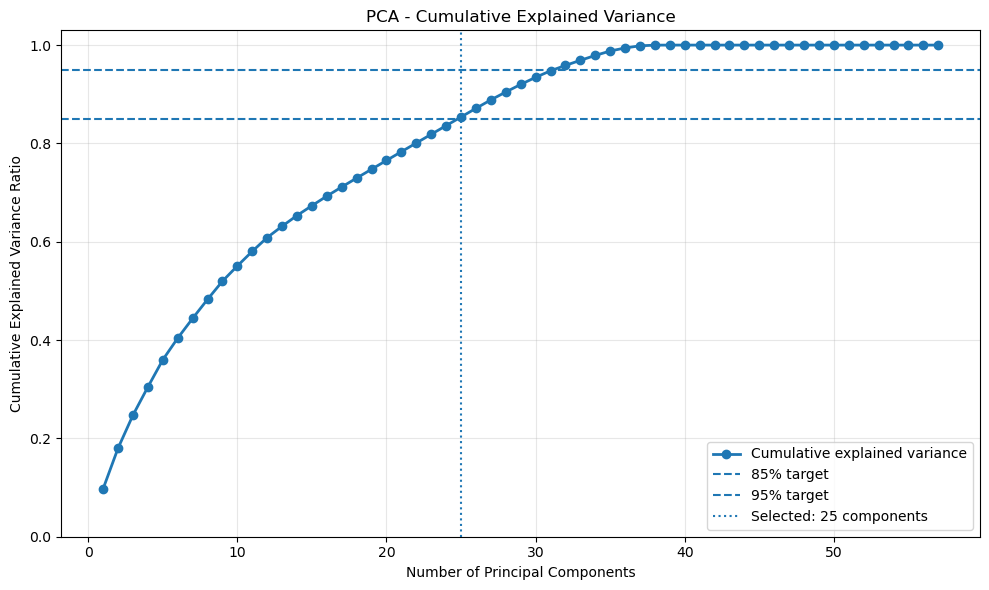

In [21]:
components = np.arange(1, len(cumulative_variance) + 1)

plt.figure(figsize=(10, 6))
plt.plot(components, cumulative_variance, marker="o", linewidth=2, label="Cumulative explained variance")
plt.axhline(0.85, linestyle="--", linewidth=1.5, label="85% target")
plt.axhline(0.95, linestyle="--", linewidth=1.5, label="95% target")
plt.axvline(n_components, linestyle=":", linewidth=1.5, label=f"Selected: {n_components} components")

plt.title("PCA - Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.ylim(0, 1.03)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 10. Biểu đồ phương sai của từng thành phần

### So What? — Ý nghĩa biểu đồ

Biểu đồ cột thể hiện tỷ lệ phương sai riêng lẻ của từng thành phần chính. PC1 thường giữ phần phương sai lớn nhất, các thành phần sau lần lượt giữ phần còn lại. Biểu đồ này giúp nhìn rõ mức đóng góp của từng thành phần và hỗ trợ giải thích vì sao có thể giảm số chiều mà vẫn giữ được phần lớn biến thiên của dữ liệu.


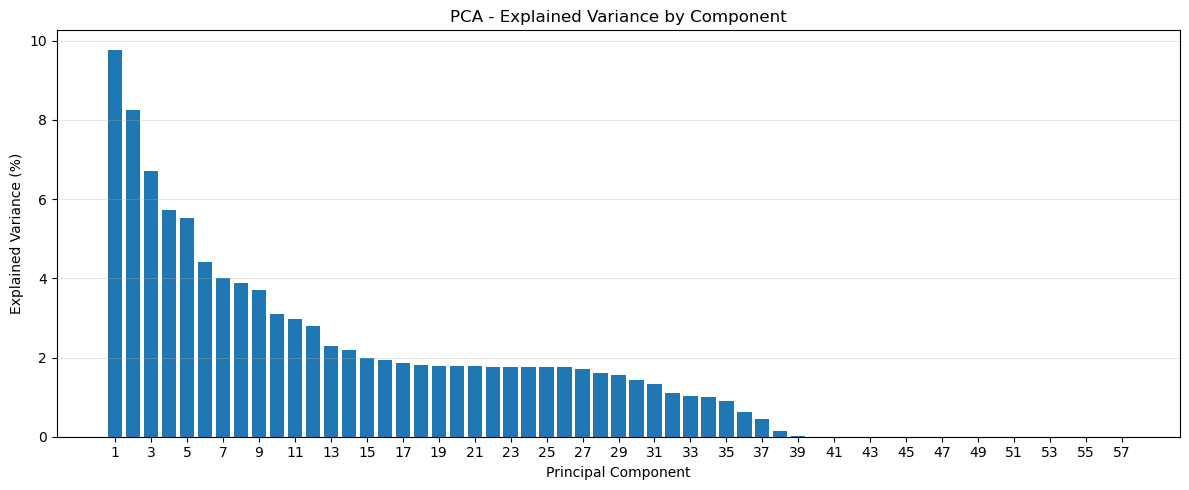

In [22]:
plt.figure(figsize=(12, 5))
plt.bar(components, explained_variance * 100)

plt.title("PCA - Explained Variance by Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.xticks(components[::max(1, len(components)//20)])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Chiếu dữ liệu lên các thành phần chính đã chọn

Tạo ma trận PCA có số thành phần đã chọn ở bước trên. `df_pca` là dataset sau giảm chiều; mỗi cột `PC1`, `PC2`, ... là một thành phần chính mới.


In [23]:
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

pca_columns = [f"PC{i}" for i in range(1, n_components + 1)]
df_pca = pd.DataFrame(X_pca, columns=pca_columns, index=df.index)

print("Số đặc trưng trước PCA:", X_scaled.shape[1])
print("Số thành phần sau PCA:", df_pca.shape[1])
print(f"Phương sai giữ lại: {pca.explained_variance_ratio_.sum():.2%}")

display(df_pca.head())


Số đặc trưng trước PCA: 57
Số thành phần sau PCA: 25
Phương sai giữ lại: 85.38%


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25
0,-2.707712,4.790861,0.161704,-0.659364,0.296295,-0.075878,1.005484,-0.884608,1.540959,-2.236279,-3.037645,-0.491603,-1.037990,-1.651356,-1.791706,-0.293159,-0.752915,-1.864031,0.848051,3.008151,-0.700764,2.688407,0.855961,-0.907663,-0.234921
1,-3.168422,-2.276626,-1.178454,2.569261,1.181923,2.735661,-0.248027,-0.671508,-0.442721,-2.112849,-1.667297,-0.120012,-0.358108,-0.988841,-0.191202,0.707275,1.020462,-0.115892,0.152185,0.085041,-0.925857,0.176390,-1.976880,1.298072,-0.388286
2,-3.438450,-2.713909,-0.215170,0.519931,0.136968,3.273914,-0.773759,-1.404559,-0.264249,-0.757613,-1.114681,-0.521727,-0.145942,-0.261717,0.596521,-0.152153,0.905922,-0.141756,0.048379,-0.049671,0.087379,0.184062,0.336404,-0.239748,-0.021830
3,2.155350,-0.086598,0.027964,-0.302171,0.026462,0.297379,-0.201556,0.096294,-0.056755,-0.987265,-1.006984,-0.922170,-0.303234,0.617929,-1.086798,-0.678000,0.238726,-0.151372,0.009917,-0.007947,-0.034332,0.040068,0.048968,-0.053554,-0.028673
4,2.163451,-0.085711,0.058681,-0.327334,0.021568,0.186618,-0.224276,0.108459,0.000747,-1.037358,-1.018263,-0.857600,-0.167380,0.483531,-0.874851,-0.338018,0.453027,-0.078272,0.001693,-0.028902,-0.047000,0.085377,0.068267,-0.052213,-0.048290


## 12. Biểu đồ phân tán PC1–PC2

Biểu đồ 2D cho thấy các dòng dữ liệu khi được chiếu lên hai thành phần chính đầu tiên. Do dataset hiện không có nhãn cụm, biểu đồ này không tô màu theo nhóm. Việc tô màu theo nhãn cụm sẽ thực hiện ở Task 2 sau khi chạy K-Means.

### So What? — Ý nghĩa biểu đồ

Các điểm gần nhau trên mặt phẳng PC1–PC2 có cấu trúc đặc trưng tương tự nhau theo hai thành phần đang quan sát. Những vùng điểm dày đặc có thể gợi ý các nhóm quan sát tương đồng, nhưng không thể kết luận đó là các cụm thật chỉ từ hình ảnh này. Task 2 sẽ dùng K-Means và các chỉ số như WCSS, Silhouette Score để đánh giá việc phân cụm. Biểu đồ chỉ thể hiện hai thành phần đầu, nên một phần thông tin có thể nằm ở các thành phần khác.


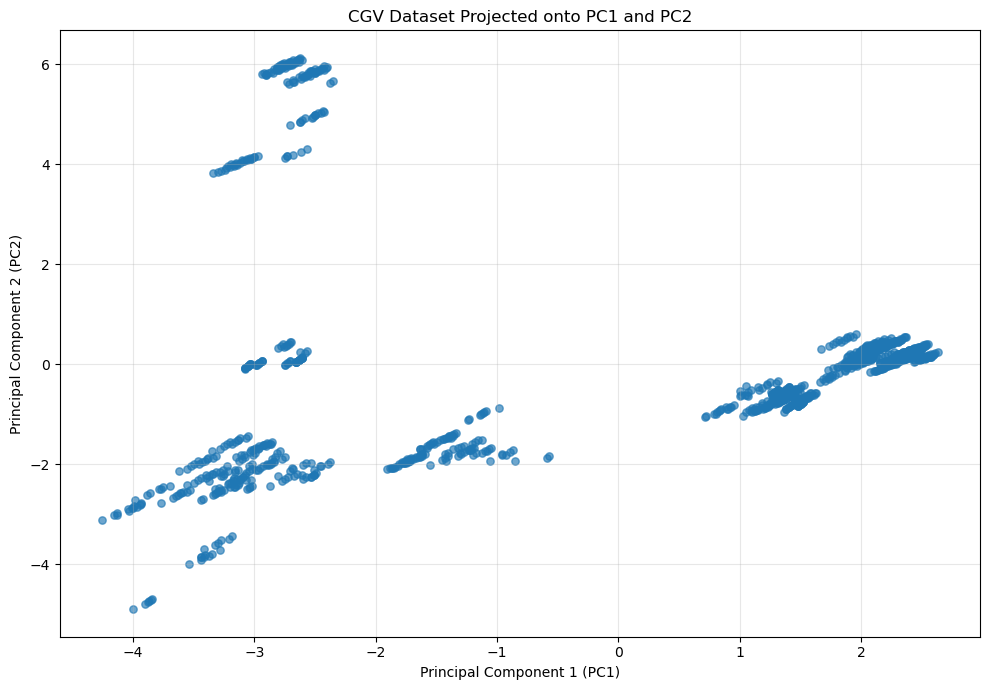

In [24]:
if X_pca.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.65, s=28)

    plt.title("CGV Dataset Projected onto PC1 and PC2")
    plt.xlabel("Principal Component 1 (PC1)")
    plt.ylabel("Principal Component 2 (PC2)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Chỉ có một thành phần PCA; không thể tạo biểu đồ PC1-PC2.")


## 13. Lưu kết quả để dùng tiếp cho Task 2

Notebook sẽ lưu:
- `cgv_pca_transformed.csv`: dữ liệu sau giảm chiều, dùng làm đầu vào cho K-Means có PCA.
- `cgv_features_encoded.csv`: đặc trưng đã mã hóa trước chuẩn hóa.
- `cgv_features_scaled.csv`: đặc trưng đã chuẩn hóa, dùng làm đầu vào cho K-Means không PCA.
- `pca_model.joblib` và `scaler_model.joblib`: mô hình PCA và scaler đã khớp với dữ liệu.
- `pca_variance_report.csv`: bảng phương sai giải thích.

Giữ các file này cùng thư mục dự án để Task 2 có thể đọc lại và so sánh hai cách phân cụm.


In [25]:
# Xuất dữ liệu và mô hình
df_pca.to_csv("cgv_pca_transformed.csv", index=False, encoding="utf-8-sig")
X.to_csv("cgv_features_encoded.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(X_scaled, columns=X.columns, index=df.index).to_csv(
    "cgv_features_scaled.csv", index=False, encoding="utf-8-sig"
)
variance_table.to_csv("pca_variance_report.csv", index=False, encoding="utf-8-sig")

joblib.dump(scaler, "scaler_model.joblib")
joblib.dump(pca, "pca_model.joblib")

print("Đã lưu các file:")
print("- cgv_pca_transformed.csv")
print("- cgv_features_encoded.csv")
print("- cgv_features_scaled.csv")
print("- pca_variance_report.csv")
print("- scaler_model.joblib")
print("- pca_model.joblib")


Đã lưu các file:
- cgv_pca_transformed.csv
- cgv_features_encoded.csv
- cgv_features_scaled.csv
- pca_variance_report.csv
- scaler_model.joblib
- pca_model.joblib


## 14. Kết luận Task 1

Sau khi chạy toàn bộ Notebook, hãy điền số liệu thực tế từ kết quả chạy vào phần báo cáo:

- Dataset đầu vào có **1.172 dòng** theo file được cung cấp.
- Sau mã hóa, số đặc trưng đầu vào PCA là: **xem kết quả Cell 5**.
- Số thành phần tối thiểu để đạt 85% phương sai: **xem kết quả Cell 8**.
- Phương sai tích lũy giữ lại sau khi chọn thành phần: **xem kết quả Cell 8**.
- Kết quả trực quan gồm biểu đồ phương sai tích lũy, phương sai từng thành phần và phân tán PC1–PC2.

**Không ghi số thành phần hoặc tỷ lệ phương sai cố định trước khi chạy Notebook**, vì kết quả phụ thuộc vào dữ liệu và cách mã hóa đặc trưng.

